# Modelo 08 - Mercado latente de aluguel por município

```

Modelo 08 - Mercado latente de aluguel por município

Pergunta: em quais cidades o mercado de aluguel anunciado é MENOR do que o perfil
socioeconômico da cidade indica? São praças sub-exploradas: há cliente potencial,
mas a oferta organizada (imobiliária anunciando aluguel) ainda não chegou. É onde
mídia de CAPTAÇÃO DE IMOBILIÁRIA tende a ter mais espaço.

Duas bases:
  - Base pública de municípios (POC de clusterização): 687 municípios com 50 mil+
    habitantes, indicadores de CNPJ, CAGED, Banco Central, Anatel, Senatran,
    CadÚnico, IBGE e o cluster (tipo de praça). -> VARIÁVEIS (X)
  - Base de anúncios fornecida pela Loft (mesmo CSV do 03). -> ALVO (y)

Abordagem supervisionada (regressão):
  unidade   = município
  alvo      = log(1 + anúncios de aluguel residencial por 10 mil habitantes)
  resultado = mercado ESPERADO (previsão fora da amostra) x mercado OBSERVADO

Separar oportunidade de falha de cobertura:
  A base da Loft vem de portais de anúncio. Se uma cidade tem pouco ALUGUEL e também
  pouca VENDA anunciada, o mais provável é o portal cobrir mal a cidade (ex.: Brasília).
  Por isso o mesmo modelo é treinado para anúncios de venda: só é "mercado latente"
  a cidade com aluguel abaixo do esperado e venda dentro do esperado.

Validação:
  - KFold 5 partes x 5 repetições (município novo)
  - GroupKFold por UF (estado que o modelo nunca viu): teste mais duro
  - baselines: média geral, mediana da UF e mediana do cluster (calculadas só no treino)

Entradas:
  DATA_DIR/<base Loft>                       (mesmo CSV do 03)
  DATA_DIR/base_municipios_POC.csv           (base pública de municípios)
  reports/tables/qualidade_meses_aluguel.csv (gerado pelo 03: janela de meses)
  reports/tables/potencial_cidades.csv       (gerado pelo 03: aluguel mediano)

Saídas:
  reports/tables/08_comparacao_modelos.csv
  reports/tables/08_importancia_variaveis.csv
  reports/tables/08_mercado_latente_municipios.csv
  reports/tables/08_mercado_esperado_fora_da_base.csv
  reports/figures/08_observado_vs_esperado.png
  reports/figures/08_top_mercado_latente.png
```

## Imports

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## Parâmetros

In [2]:
ARQUIVO_LOFT = "bq-results-20261005-170605-1791220258075.csv"
ARQUIVO_MUNICIPIOS = "base_municipios_POC.csv"

SEMENTE = 42
N_PARTES = 5
N_REPETICOES = 5

TIPO_RESIDENCIAL = "apartment_house"      # apartamento + casa (ver 03)
POPULACAO_MINIMA_RANKING = 100_000        # o ranking final foca em praças de porte relevante

# Leitura da razão observado / esperado
LIMITE_LATENTE_FORTE = 0.5                # observado < metade do esperado
LIMITE_LATENTE = 0.8
LIMITE_ACIMA = 1.25
LIMITE_COBERTURA_VENDA = 0.5              # venda < metade do esperado = portal cobre mal a cidade

# Variáveis públicas usadas (as 16 da POC de clusterização + 4 descritoras)
VARIAVEIS_PUBLICAS = [
    "administradoras_10k", "imobiliarias_10k", "imobiliarias_novas_pct",
    "pix_pf_por_hab", "salario_admissao", "cadunico_pct", "credito_per_capita",
    "veiculos_por_hab", "saldo_emprego_pct", "internet_movel_100", "banda_larga_100",
    "alavancagem", "reserva_per_capita", "corretores_seguros_10k",
    "crescimento_populacional_pct", "jovens_admissoes_pct",
    "financiamento_imob_per_capita", "motos_por_hab",
    "domicilios_alugados_pct_uf", "inadimplencia_pf_uf",
]

## Caminhos

In [3]:
# No notebook não existe __file__: o projeto é a pasta acima de notebooks/
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_DIR / ".env")

caminho_dados = os.getenv("DATA_DIR")
if caminho_dados is None:
    raise ValueError("A variável DATA_DIR não foi encontrada. Confira o arquivo .env.")

DATA_DIR = Path(caminho_dados)
ARQUIVO = DATA_DIR / os.getenv("LOFT_FILE", ARQUIVO_LOFT)
ARQUIVO_MUN = DATA_DIR / os.getenv("MUNICIPIOS_FILE", ARQUIVO_MUNICIPIOS)

TABLES_DIR = PROJECT_DIR / "reports" / "tables"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

ARQUIVO_QUALIDADE = TABLES_DIR / "qualidade_meses_aluguel.csv"
ARQUIVO_POTENCIAL = TABLES_DIR / "potencial_cidades.csv"

for arquivo, dica in [
    (ARQUIVO, "coloque o CSV da Loft na pasta DATA_DIR"),
    (ARQUIVO_MUN, "coloque base_municipios_POC.csv na pasta DATA_DIR"),
    (ARQUIVO_QUALIDADE, "rode antes o notebook 03_potencial_mercado"),
    (ARQUIVO_POTENCIAL, "rode antes o notebook 03_potencial_mercado"),
]:
    if not arquivo.exists():
        raise FileNotFoundError(f"{arquivo.name} não encontrado: {dica}.")

## Leitura da base pública de municípios

In [4]:
municipios = pd.read_csv(ARQUIVO_MUN, dtype={"id_municipio": str})

print("Municípios na base pública:", len(municipios))
print("Tipos de praça (cluster):")
print(municipios["tipo_de_praca"].value_counts().to_string())

Municípios na base pública: 687
Tipos de praça (cluster):
tipo_de_praca
Praça intermediária conectada    219
Praça popular de grande porte    167
Praça madura de locação          131
Praça sem mercado formal          97
Praça em formação                 73


## Leitura da base loft: anúncios por cidade na janela do 03

In [5]:
qualidade = pd.read_csv(ARQUIVO_QUALIDADE, parse_dates=["mes"])
janela = qualidade.loc[qualidade["na_janela"], "mes"]

loft = pd.read_csv(
    ARQUIVO,
    usecols=["snapshot_month", "normalized_state_seed", "normalized_city_seed",
             "operation_type", "property_type_group", "n_listings"],
    dtype={"normalized_state_seed": str, "normalized_city_seed": str,
           "operation_type": str, "property_type_group": str},
    parse_dates=["snapshot_month"],
)

loft = loft[loft["snapshot_month"].isin(janela) & (loft["property_type_group"] == TIPO_RESIDENCIAL)]

# Média mensal de anúncios de aluguel e de venda por cidade
anuncios_cidade = (
    loft.pivot_table(
        index=["normalized_state_seed", "normalized_city_seed"],
        columns="operation_type",
        values="n_listings",
        aggfunc="sum",
        fill_value=0,
    )
    .div(len(janela))
    .rename(columns={"rent": "anuncios_aluguel_mes", "sale": "anuncios_venda_mes"})
    .reset_index()
    .rename(columns={"normalized_state_seed": "sigla_uf", "normalized_city_seed": "cidade"})
)

print("\nJanela:", [m.strftime("%Y-%m") for m in janela])
print("Cidades na base Loft:", len(anuncios_cidade))


Janela: ['2026-01', '2026-04', '2026-05', '2026-06', '2026-07', '2026-08']
Cidades na base Loft: 530


## Junção das duas bases (nome normalizado + uf)

In [6]:
def normalizar_nome(serie):
    """'São José dos Campos' -> 'SAO JOSE DOS CAMPOS' (sem acento, maiúsculo)."""
    return (
        serie.astype(str)
        .str.normalize("NFKD")
        .str.encode("ascii", errors="ignore")
        .str.decode("ascii")
        .str.upper()
        .str.replace(r"[^A-Z ]", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )


municipios["chave"] = normalizar_nome(municipios["municipio"])
anuncios_cidade["chave"] = normalizar_nome(anuncios_cidade["cidade"])

potencial = pd.read_csv(ARQUIVO_POTENCIAL)
potencial["chave"] = normalizar_nome(potencial["cidade"])
potencial = potencial.rename(columns={"uf": "sigla_uf"})[["sigla_uf", "chave", "aluguel_mediano"]]

base = (
    municipios
    .merge(anuncios_cidade.drop(columns="cidade"), on=["sigla_uf", "chave"], how="left")
    .merge(potencial, on=["sigla_uf", "chave"], how="left")
)
base["coberta_pela_loft"] = base["anuncios_aluguel_mes"].notna()

# Conferência: cidades relevantes da Loft que não acharam município
casadas = anuncios_cidade.merge(municipios[["sigla_uf", "chave"]], on=["sigla_uf", "chave"], how="left", indicator=True)
nao_casadas = casadas[(casadas["_merge"] == "left_only") & (casadas["anuncios_aluguel_mes"] >= 50)]

print("\nMunicípios presentes nas duas bases:", base["coberta_pela_loft"].sum())
print("Municípios só na base pública (fora da Loft):", (~base["coberta_pela_loft"]).sum())
print("Cidades da Loft com 50+ anúncios/mês sem município correspondente:", len(nao_casadas))
print("(municípios com menos de 50 mil habitantes não estão na base pública)")


Municípios presentes nas duas bases: 358
Municípios só na base pública (fora da Loft): 329
Cidades da Loft com 50+ anúncios/mês sem município correspondente: 2
(municípios com menos de 50 mil habitantes não estão na base pública)


## Alvos: anúncios por 10 mil habitantes

In [7]:
base["aluguel_10k"] = base["anuncios_aluguel_mes"] / base["populacao"] * 10_000
base["venda_10k"] = base["anuncios_venda_mes"] / base["populacao"] * 10_000

# log(1 + x): a distribuição tem cauda longa e vários valores perto de zero
base["alvo_aluguel"] = np.log1p(base["aluguel_10k"])
base["alvo_venda"] = np.log1p(base["venda_10k"])

print("\nAnúncios de aluguel por 10 mil habitantes (municípios na Loft):")
print(base.loc[base["coberta_pela_loft"], "aluguel_10k"].describe().round(2).to_string())


Anúncios de aluguel por 10 mil habitantes (municípios na Loft):
count    358.00
mean      16.33
std       30.59
min        0.00
25%        0.46
50%        4.13
75%       16.06
max      184.80


## Variáveis

In [8]:
base["log_populacao"] = np.log(base["populacao"])

dummies_cluster = pd.get_dummies(base["tipo_de_praca"], prefix="praca", dtype=float)
dummies_regiao = pd.get_dummies(base["regiao"], prefix="regiao", dtype=float)
base = pd.concat([base, dummies_cluster, dummies_regiao], axis=1)

VARIAVEIS = (
    ["log_populacao"]
    + [v for v in VARIAVEIS_PUBLICAS if v in base.columns]
    + list(dummies_cluster.columns)
    + list(dummies_regiao.columns)
)

treino = base[base["coberta_pela_loft"]].reset_index(drop=True)
fora = base[~base["coberta_pela_loft"]].reset_index(drop=True)

X = treino[VARIAVEIS]
y = treino["alvo_aluguel"].to_numpy()
y_venda = treino["alvo_venda"].to_numpy()
ufs = treino["sigla_uf"].to_numpy()

print("\nVariáveis usadas:", len(VARIAVEIS))
print(f"Treino: {len(treino)} municípios | Fora da base Loft: {len(fora)}")
print("Faltantes nas variáveis (preenchidos pela mediana dentro do pipeline):", int(X.isna().sum().sum()))


Variáveis usadas: 31
Treino: 358 municípios | Fora da base Loft: 329
Faltantes nas variáveis (preenchidos pela mediana dentro do pipeline): 0


## Modelos

In [9]:
def modelos():
    # SimpleImputer dentro do pipeline: a mediana é calculada só com o treino de cada partição
    return {
        "Regressão Ridge": make_pipeline(
            SimpleImputer(strategy="median"), StandardScaler(),
            RidgeCV(alphas=np.logspace(-2, 3, 30)),
        ),
        "Random Forest": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestRegressor(n_estimators=500, min_samples_leaf=3, max_features=0.5,
                                  random_state=SEMENTE, n_jobs=-1),
        ),
        "Gradient Boosting": make_pipeline(
            SimpleImputer(strategy="median"),
            HistGradientBoostingRegressor(max_iter=300, learning_rate=0.03, min_samples_leaf=15,
                                          l2_regularization=1.0, random_state=SEMENTE),
        ),
    }


def baselines(alvo, idx_tr, idx_te):
    """Previsões sem modelo, calculadas só com o treino da partição."""
    tr, te = treino.iloc[idx_tr], treino.iloc[idx_te]
    geral = np.median(alvo[idx_tr])
    saida = {"Baseline média geral": np.full(len(idx_te), alvo[idx_tr].mean())}
    for coluna, nome in [("sigla_uf", "Baseline mediana da UF"), ("tipo_de_praca", "Baseline mediana do cluster")]:
        medianas = pd.Series(alvo[idx_tr]).groupby(tr[coluna].to_numpy()).median()
        saida[nome] = te[coluna].map(medianas).fillna(geral).to_numpy()
    return saida


def previsoes_fora_da_amostra(alvo, divisor, grupos=None, repeticoes=1):
    """Cada município recebe a previsão de um modelo que não o viu no treino."""
    soma = {}
    for r in range(repeticoes):
        if isinstance(divisor, KFold):
            divisor = KFold(N_PARTES, shuffle=True, random_state=SEMENTE + r)
        for idx_tr, idx_te in divisor.split(X, alvo, grupos):
            for nome, pred in baselines(alvo, idx_tr, idx_te).items():
                soma.setdefault(nome, np.zeros(len(alvo)))[idx_te] += pred
            for nome, modelo in modelos().items():
                modelo.fit(X.iloc[idx_tr], alvo[idx_tr])
                soma.setdefault(nome, np.zeros(len(alvo)))[idx_te] += modelo.predict(X.iloc[idx_te])
    return {nome: v / repeticoes for nome, v in soma.items()}


def avaliar(alvo, previsoes, validacao):
    return [
        {
            "validacao": validacao,
            "modelo": nome,
            "RMSE_log": np.sqrt(mean_squared_error(alvo, pred)),
            "MAE_log": mean_absolute_error(alvo, pred),
            "R2": r2_score(alvo, pred),
        }
        for nome, pred in previsoes.items()
    ]

## Validação do modelo de aluguel

In [10]:
oof_kfold = previsoes_fora_da_amostra(y, KFold(N_PARTES), repeticoes=N_REPETICOES)
oof_uf = previsoes_fora_da_amostra(y, GroupKFold(N_PARTES), grupos=ufs)

comparacao = pd.DataFrame(
    avaliar(y, oof_kfold, f"KFold {N_PARTES}x{N_REPETICOES}")
    + avaliar(y, oof_uf, "Agrupada por UF (estado nunca visto)")
)

print("\n============================")
print("COMPARAÇÃO DOS MODELOS - ALUGUEL (fora da amostra)")
print("============================")
print(comparacao.sort_values(["validacao", "RMSE_log"]).round(4).to_string(index=False))

kfold = comparacao[comparacao["validacao"].str.startswith("KFold")]
aprendidos = kfold[~kfold["modelo"].str.startswith("Baseline")]
MELHOR = aprendidos.loc[aprendidos["RMSE_log"].idxmin(), "modelo"]
melhor_baseline = kfold[kfold["modelo"].str.startswith("Baseline")].sort_values("RMSE_log").iloc[0]

print(f"\nMelhor modelo: {MELHOR}")
print(f"Melhor baseline: {melhor_baseline['modelo']} (R² {melhor_baseline['R2']:.3f})")


COMPARAÇÃO DOS MODELOS - ALUGUEL (fora da amostra)
                           validacao                      modelo  RMSE_log  MAE_log      R2
Agrupada por UF (estado nunca visto)               Random Forest    0.9247   0.7356  0.5998
Agrupada por UF (estado nunca visto)           Gradient Boosting    0.9948   0.7679  0.5369
Agrupada por UF (estado nunca visto)             Regressão Ridge    1.1296   0.8762  0.4029
Agrupada por UF (estado nunca visto) Baseline mediana do cluster    1.2266   0.9769  0.2959
Agrupada por UF (estado nunca visto)        Baseline média geral    1.5396   1.3003 -0.1093
Agrupada por UF (estado nunca visto)      Baseline mediana da UF    1.5666   1.3057 -0.1485
                           KFold 5x5           Gradient Boosting    0.7459   0.5608  0.7397
                           KFold 5x5               Random Forest    0.7823   0.6188  0.7136
                           KFold 5x5             Regressão Ridge    0.8640   0.6661  0.6507
                           K

## Importância das variáveis (permutação, sobre o melhor modelo)

In [11]:
modelo_final = modelos()[MELHOR]
modelo_final.fit(X, y)

perm = permutation_importance(
    modelo_final, X, y, n_repeats=20, random_state=SEMENTE, scoring="neg_root_mean_squared_error"
)
importancia = pd.DataFrame({
    "variavel": VARIAVEIS,
    "aumento_RMSE_ao_embaralhar": perm.importances_mean,
    "desvio": perm.importances_std,
}).sort_values("aumento_RMSE_ao_embaralhar", ascending=False)

print("\nImportância das variáveis (top 10):")
print(importancia.head(10).round(4).to_string(index=False))


Importância das variáveis (top 10):
                    variavel  aumento_RMSE_ao_embaralhar  desvio
               log_populacao                      0.7671  0.0324
            imobiliarias_10k                      0.6611  0.0256
      corretores_seguros_10k                      0.1925  0.0090
            veiculos_por_hab                      0.1398  0.0066
          credito_per_capita                      0.1389  0.0093
          internet_movel_100                      0.1346  0.0091
crescimento_populacional_pct                      0.1326  0.0079
            salario_admissao                      0.1306  0.0072
        jovens_admissoes_pct                      0.1142  0.0091
             banda_larga_100                      0.1098  0.0080


## Checagem de cobertura: o mesmo modelo para anúncios de venda

In [12]:
# Só a previsão fora da amostra do melhor modelo (KFold) é necessária aqui
oof_venda = np.zeros(len(y_venda))
for r in range(N_REPETICOES):
    for idx_tr, idx_te in KFold(N_PARTES, shuffle=True, random_state=SEMENTE + r).split(X):
        modelo = modelos()[MELHOR]
        modelo.fit(X.iloc[idx_tr], y_venda[idx_tr])
        oof_venda[idx_te] += modelo.predict(X.iloc[idx_te])
oof_venda /= N_REPETICOES

print(f"\nModelo de VENDA ({MELHOR}): R² fora da amostra = {r2_score(y_venda, oof_venda):.3f}")


Modelo de VENDA (Gradient Boosting): R² fora da amostra = 0.726


## Mercado latente (resíduo fora da amostra)

In [13]:
treino["aluguel_esperado_10k"] = np.expm1(oof_kfold[MELHOR])
treino["venda_esperada_10k"] = np.expm1(oof_venda)

treino["razao_aluguel"] = treino["aluguel_10k"] / treino["aluguel_esperado_10k"]
treino["razao_venda"] = treino["venda_10k"] / treino["venda_esperada_10k"]

treino["anuncios_aluguel_esperados_mes"] = treino["aluguel_esperado_10k"] * treino["populacao"] / 10_000
treino["lacuna_anuncios_mes"] = treino["anuncios_aluguel_esperados_mes"] - treino["anuncios_aluguel_mes"]
treino["lacuna_volume_aluguel_mes"] = treino["lacuna_anuncios_mes"] * treino["aluguel_mediano"]


def leitura(linha):
    if linha["razao_aluguel"] < LIMITE_LATENTE and linha["razao_venda"] < LIMITE_COBERTURA_VENDA:
        return "Possível falha de cobertura da base"
    if linha["razao_aluguel"] < LIMITE_LATENTE_FORTE:
        return "Mercado latente forte"
    if linha["razao_aluguel"] < LIMITE_LATENTE:
        return "Mercado latente"
    if linha["razao_aluguel"] <= LIMITE_ACIMA:
        return "Dentro do esperado"
    return "Acima do esperado (mercado desenvolvido)"


treino["leitura"] = treino.apply(leitura, axis=1)

latente = treino[[
    "id_municipio", "municipio", "sigla_uf", "regiao", "populacao", "tipo_de_praca",
    "anuncios_aluguel_mes", "anuncios_aluguel_esperados_mes",
    "aluguel_10k", "aluguel_esperado_10k", "razao_aluguel",
    "venda_10k", "venda_esperada_10k", "razao_venda",
    "lacuna_anuncios_mes", "aluguel_mediano", "lacuna_volume_aluguel_mes", "leitura",
]].sort_values("lacuna_anuncios_mes", ascending=False)

print("\nDistribuição das leituras:")
print(latente["leitura"].value_counts().to_string())

ranking = latente[
    latente["leitura"].str.startswith("Mercado latente")
    & (latente["populacao"] >= POPULACAO_MINIMA_RANKING)
]

print(f"\nTop 15 mercados latentes (municípios com {POPULACAO_MINIMA_RANKING // 1000} mil+ habitantes):")
print(ranking.head(15)[[
    "municipio", "sigla_uf", "tipo_de_praca", "anuncios_aluguel_mes",
    "anuncios_aluguel_esperados_mes", "razao_aluguel", "razao_venda",
]].round(2).to_string(index=False))

cobertura = latente[latente["leitura"] == "Possível falha de cobertura da base"]
print("\nMaiores municípios com possível falha de cobertura (fora do ranking):")
print(cobertura.sort_values("populacao", ascending=False).head(8)[
    ["municipio", "sigla_uf", "populacao", "razao_aluguel", "razao_venda"]
].round(2).to_string(index=False))


Distribuição das leituras:
leitura
Acima do esperado (mercado desenvolvido)    128
Possível falha de cobertura da base          95
Dentro do esperado                           54
Mercado latente forte                        45
Mercado latente                              36

Top 15 mercados latentes (municípios com 100 mil+ habitantes):
           municipio sigla_uf                 tipo_de_praca  anuncios_aluguel_mes  anuncios_aluguel_esperados_mes  razao_aluguel  razao_venda
            Curitiba       PR       Praça madura de locação               4728.00                        15243.87           0.31         0.56
       Caxias do Sul       RS Praça intermediária conectada               1281.67                         3551.49           0.36         0.86
           Fortaleza       CE       Praça madura de locação               2956.67                         4547.82           0.65         1.02
        Campo Grande       MS       Praça madura de locação                450.00           

## Leitura por tipo de praça (cluster)

In [14]:
por_praca = (
    latente.groupby("tipo_de_praca")
    .agg(
        municipios=("municipio", "size"),
        razao_mediana=("razao_aluguel", "median"),
        latentes=("leitura", lambda s: s.str.startswith("Mercado latente").sum()),
    )
    .reset_index()
)
por_praca["pct_latentes"] = por_praca["latentes"] / por_praca["municipios"] * 100

print("\nMercado latente por tipo de praça:")
print(por_praca.round(2).to_string(index=False))


Mercado latente por tipo de praça:
                tipo_de_praca  municipios  razao_mediana  latentes  pct_latentes
            Praça em formação          21           0.42         6         28.57
Praça intermediária conectada         139           0.84        35         25.18
      Praça madura de locação          89           1.18        17         19.10
Praça popular de grande porte          94           0.70        19         20.21
     Praça sem mercado formal          15           0.00         4         26.67


## Municípios fora da base loft: quanto mercado se esperaria?

In [15]:
fora["aluguel_esperado_10k"] = np.expm1(modelo_final.predict(fora[VARIAVEIS]))
fora["anuncios_aluguel_esperados_mes"] = fora["aluguel_esperado_10k"] * fora["populacao"] / 10_000

esperado_fora = fora[[
    "id_municipio", "municipio", "sigla_uf", "populacao", "tipo_de_praca",
    "aluguel_esperado_10k", "anuncios_aluguel_esperados_mes",
]].sort_values("anuncios_aluguel_esperados_mes", ascending=False)

print("\nMunicípios fora da base Loft com maior mercado esperado:")
print(esperado_fora.head(10).round(1).to_string(index=False))


Municípios fora da base Loft com maior mercado esperado:
id_municipio     municipio sigla_uf  populacao                 tipo_de_praca  aluguel_esperado_10k  anuncios_aluguel_esperados_mes
     3505708       Barueri       SP     336015       Praça madura de locação                 109.1                          3666.9
     3504107       Atibaia       SP     168162       Praça madura de locação                 106.9                          1797.3
     3518701       Guarujá       SP     294780       Praça madura de locação                  54.2                          1596.6
     4211900       Palhoça       SC     261287       Praça madura de locação                  49.6                          1295.8
     3520509    Indaiatuba       SP     271322       Praça madura de locação                  46.2                          1254.1
     4108304 Foz do Iguaçu       PR     299112       Praça madura de locação                  25.6                           764.7
     3523909           It

## Salvar

In [16]:
comparacao.to_csv(TABLES_DIR / "08_comparacao_modelos.csv", index=False)
importancia.to_csv(TABLES_DIR / "08_importancia_variaveis.csv", index=False)
latente.to_csv(TABLES_DIR / "08_mercado_latente_municipios.csv", index=False)
esperado_fora.to_csv(TABLES_DIR / "08_mercado_esperado_fora_da_base.csv", index=False)

print("\nTabelas salvas em:", TABLES_DIR)


Tabelas salvas em: c:\Users\vjuli\OneDrive\Documentos\ibmecPCDV20261_victor_lucas_beatriz_ravi\reports\tables


## Gráfico - observado x esperado

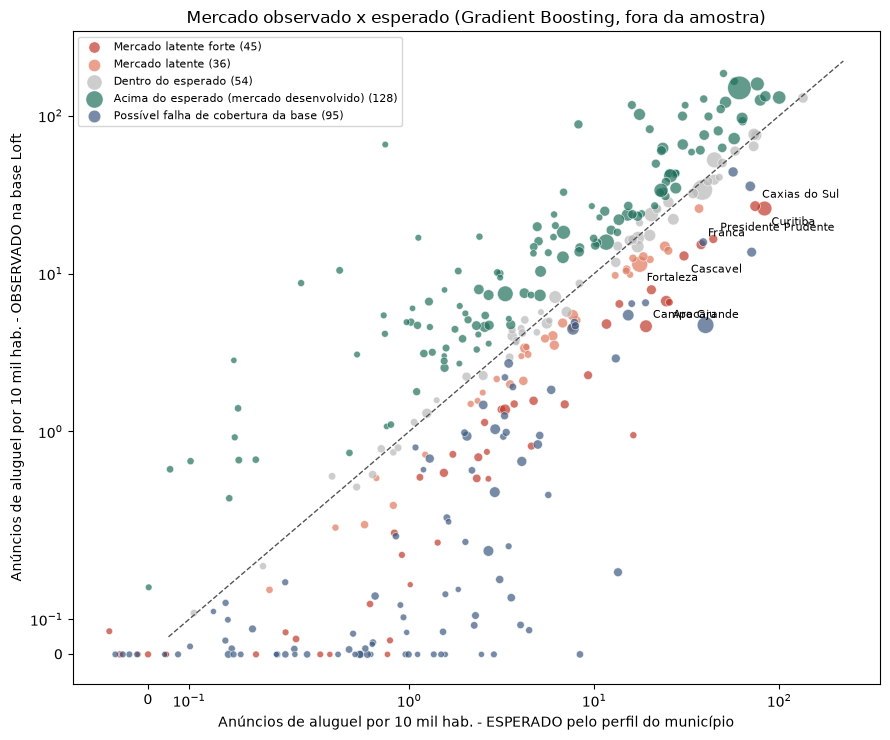

In [17]:
cores_leitura = {
    "Mercado latente forte": "#c0392b",
    "Mercado latente": "#e07a5f",
    "Dentro do esperado": "#b8b8b8",
    "Acima do esperado (mercado desenvolvido)": "#1f6f5c",
    "Possível falha de cobertura da base": "#3d5a80",
}

fig, ax = plt.subplots(figsize=(9, 7.5))
for nome, cor in cores_leitura.items():
    parte = treino[treino["leitura"] == nome]
    ax.scatter(parte["aluguel_esperado_10k"], parte["aluguel_10k"],
               s=np.sqrt(parte["populacao"]) / 12, color=cor, alpha=0.7,
               edgecolor="white", linewidth=0.5, label=f"{nome} ({len(parte)})")

limite = [0.05, max(treino["aluguel_esperado_10k"].max(), treino["aluguel_10k"].max()) * 1.2]
ax.plot(limite, limite, color="#555", linestyle="--", linewidth=1)
ax.set_xscale("symlog", linthresh=0.5)
ax.set_yscale("symlog", linthresh=0.5)
ax.set_xlabel("Anúncios de aluguel por 10 mil hab. - ESPERADO pelo perfil do município")
ax.set_ylabel("Anúncios de aluguel por 10 mil hab. - OBSERVADO na base Loft")
ax.set_title(f"Mercado observado x esperado ({MELHOR}, fora da amostra)")
ax.legend(fontsize=8, loc="upper left")

for i, (_, linha) in enumerate(ranking.head(8).iterrows()):
    # alterna o rótulo acima/abaixo do ponto para os nomes não se sobreporem
    ax.annotate(linha["municipio"], (linha["aluguel_esperado_10k"], linha["aluguel_10k"]),
                fontsize=8, xytext=(5, 6 if i % 2 else -12), textcoords="offset points")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_observado_vs_esperado.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

## Gráfico - top mercados latentes

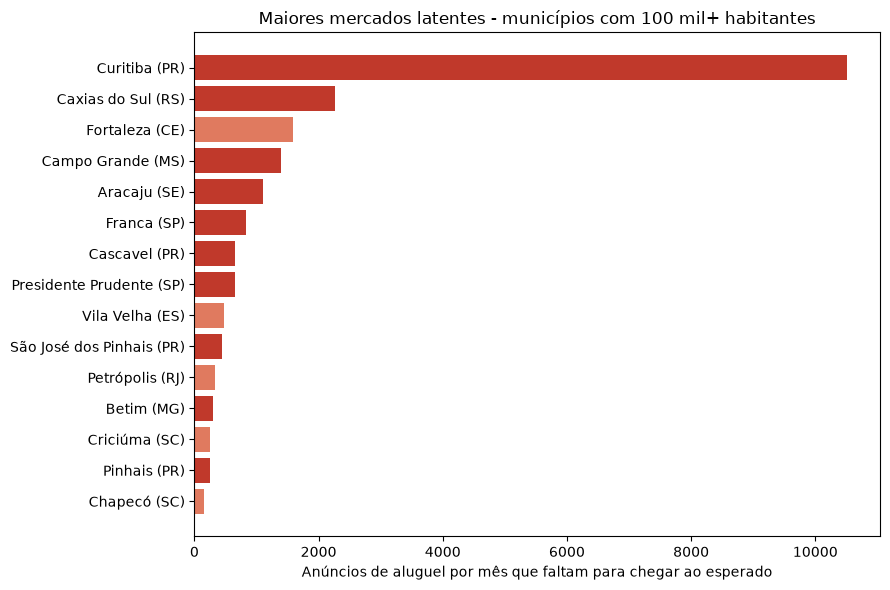

In [18]:
top = ranking.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["municipio"] + " (" + top["sigla_uf"] + ")", top["lacuna_anuncios_mes"],
        color=top["leitura"].map(cores_leitura))
ax.set_xlabel("Anúncios de aluguel por mês que faltam para chegar ao esperado")
ax.set_title(f"Maiores mercados latentes - municípios com {POPULACAO_MINIMA_RANKING // 1000} mil+ habitantes")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_top_mercado_latente.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

## Conclusão

In [19]:
melhor = kfold[kfold["modelo"] == MELHOR].iloc[0]
melhor_uf = comparacao[
    (comparacao["validacao"].str.startswith("Agrupada")) & (comparacao["modelo"] == MELHOR)
].iloc[0]
n_latentes = latente["leitura"].str.startswith("Mercado latente").sum()

print("\n============================")
print("CONCLUSÃO - MODELO 08")
print("============================")
print(
    f"{MELHOR}: R² fora da amostra de {melhor['R2']:.3f} (município novo) e "
    f"{melhor_uf['R2']:.3f} (estado nunca visto), contra {melhor_baseline['R2']:.3f} do "
    f"melhor baseline ({melhor_baseline['modelo']})."
)
print(
    f"{n_latentes} municípios têm aluguel anunciado abaixo de {LIMITE_LATENTE:.0%} do esperado "
    "para o seu perfil, com cobertura de venda normal: são as praças candidatas a mídia de "
    "captação de imobiliária."
)
print(
    f"{len(cobertura)} municípios foram separados como possível falha de cobertura da base "
    "(pouco aluguel E pouca venda anunciada)."
)
print(
    "\nCuidado de leitura: o modelo mede oferta ANUNCIADA em portais. 'Mercado latente' "
    "indica onde a oferta organizada está abaixo do perfil da cidade; deve ser tratado "
    "como lista de praças para teste de mídia, não como garantia de demanda."
)


CONCLUSÃO - MODELO 08
Gradient Boosting: R² fora da amostra de 0.740 (município novo) e 0.537 (estado nunca visto), contra 0.398 do melhor baseline (Baseline mediana do cluster).
81 municípios têm aluguel anunciado abaixo de 80% do esperado para o seu perfil, com cobertura de venda normal: são as praças candidatas a mídia de captação de imobiliária.
95 municípios foram separados como possível falha de cobertura da base (pouco aluguel E pouca venda anunciada).

Cuidado de leitura: o modelo mede oferta ANUNCIADA em portais. 'Mercado latente' indica onde a oferta organizada está abaixo do perfil da cidade; deve ser tratado como lista de praças para teste de mídia, não como garantia de demanda.
